In [6]:
import os
import json
import numpy as np
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sentence_transformers import SentenceTransformer, InputExample, losses
from torch.utils.data import DataLoader
import torch
from tqdm.auto import tqdm

print("✓ Imports complete")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

✓ Imports complete
Device: cuda


## 1. Load Training Pairs

In [7]:
DATA_DIR = Path('data_new')
train_pairs_path = DATA_DIR / 'fixed_training_pairs.json'

with open(train_pairs_path, 'r', encoding='utf-8') as f:
    train_data = json.load(f)

texts1 = train_data['texts1']
texts2 = train_data['texts2']
labels = train_data['labels']
metadata = train_data.get('metadata', {})

print(f"Loaded training pairs from {train_pairs_path}")
print(f"  Total pairs: {len(labels)}")
print(f"  Positive: {sum(labels)}")
print(f"  Negative: {len(labels) - sum(labels)}")
print(f"\nMetadata:")
print(f"  Generated at: {metadata.get('generated_at')}")
print(f"  Separability: {metadata.get('baseline_separability'):.4f}")
print(f"  Overlap: {metadata.get('baseline_overlap'):.4f}")
print(f"  Quality: {metadata.get('quality_status')}")

Loaded training pairs from data_new\fixed_training_pairs.json
  Total pairs: 10000
  Positive: 5000
  Negative: 5000

Metadata:
  Generated at: 2025-12-17 18:46:34
  Separability: 0.3742
  Overlap: 0.0000
  Quality: EXCELLENT


## 2. Load and Compare Against Baseline Model

In [8]:
# Load baseline model for comparison (force fp32 for stability)
print("Loading baseline model: sentence-transformers/all-mpnet-base-v2 (fp32)")
baseline_model = SentenceTransformer(
    'sentence-transformers/all-mpnet-base-v2',
    device=device
)

# Compute embeddings and baseline metrics on training pairs
print(f"\nEncoding training pairs with baseline model...")
embeddings1 = baseline_model.encode(texts1, batch_size=64, show_progress_bar=True, convert_to_numpy=True)
embeddings2 = baseline_model.encode(texts2, batch_size=64, show_progress_bar=True, convert_to_numpy=True)

# Sanitize embeddings
embeddings1 = np.nan_to_num(embeddings1, nan=0.0, posinf=0.0, neginf=0.0)
embeddings2 = np.nan_to_num(embeddings2, nan=0.0, posinf=0.0, neginf=0.0)

# Normalize to unit vectors
embeddings1 = embeddings1 / (np.linalg.norm(embeddings1, axis=1, keepdims=True) + 1e-12)
embeddings2 = embeddings2 / (np.linalg.norm(embeddings2, axis=1, keepdims=True) + 1e-12)

# Cosine similarity on normalized embeddings
similarities = np.sum(embeddings1 * embeddings2, axis=1)

labels_arr = np.array(labels)
pos_sims = similarities[labels_arr == 1]
neg_sims = similarities[labels_arr == 0]

baseline_sep = float(pos_sims.mean() - neg_sims.mean())
baseline_overlap = float(np.mean(pos_sims <= np.percentile(neg_sims, 95)) * 100)

print(f"\n{'='*80}")
print("BASELINE MODEL METRICS (on training pairs)")
print(f"{'='*80}")
print(f"Positive pairs mean similarity: {pos_sims.mean():.4f}")
print(f"Negative pairs mean similarity: {neg_sims.mean():.4f}")
print(f"Separability: {baseline_sep:.4f}")
print(f"Overlap (P95): {baseline_overlap:.1f}%")

Loading baseline model: sentence-transformers/all-mpnet-base-v2 (fp32)


OutOfMemoryError: CUDA out of memory. Tried to allocate 90.00 MiB. GPU 0 has a total capacity of 8.00 GiB of which 0 bytes is free. Of the allocated memory 22.15 GiB is allocated by PyTorch, and 350.14 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## 3. Load Test Pairs for Evaluation

In [ ]:
test_pairs_path = DATA_DIR / 'fixed_test_pairs.json'

with open(test_pairs_path, 'r', encoding='utf-8') as f:
    test_data = json.load(f)

test_texts1 = test_data['texts1']
test_texts2 = test_data['texts2']
test_labels = test_data['labels']
test_metadata = test_data.get('metadata', {})

print(f"Loaded test pairs from {test_pairs_path}")
print(f"  Total pairs: {len(test_labels)}")
print(f"  Positive: {sum(test_labels)}")
print(f"  Negative: {len(test_labels) - sum(test_labels)}")
print(f"\nTest metadata:")
print(f"  Separability: {test_metadata.get('baseline_separability'):.4f}")
print(f"  Quality: {test_metadata.get('quality_status')}")

Loaded test pairs from data_new\fixed_test_pairs.json
  Total pairs: 1000
  Positive: 500
  Negative: 500

Test metadata:
  Separability: 0.1865
  Quality: None


## 4. Quick Train: Fine-tune Model on Training Pairs

In [10]:
# Prepare training data as labeled pairs for ContrastiveLoss
print("Preparing training pairs for contrastive training...")

pair_examples = []
for i in range(len(labels)):
    pair_examples.append(InputExample(texts=[texts1[i], texts2[i]], label=float(labels[i])))

print(f"Created {len(pair_examples)} pair examples")

# Create data loader with smaller batch size to avoid OOM
train_dataloader = DataLoader(pair_examples, shuffle=True, batch_size=8)

# Free up ALL GPU memory before training
print("\nFreeing GPU memory...")
# Delete all models and embeddings
if 'baseline_model' in globals():
    del baseline_model
if 'model' in globals():
    del model
if 'embeddings1' in globals():
    del embeddings1
if 'embeddings2' in globals():
    del embeddings2

# Force garbage collection and clear CUDA cache
import gc
gc.collect()
if device == 'cuda':
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    print(f"GPU memory freed. Current allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

# Load a fresh copy of the model for training (force fp32 for stability)
print("\nLoading model for fine-tuning (fp32)...")
model = SentenceTransformer(
    'sentence-transformers/all-mpnet-base-v2',
    device=device
)

# Use contrastive loss (more stable than cosine for 0/1 labels)
train_loss = losses.ContrastiveLoss(model=model)

# Fine-tune with gradient accumulation to simulate larger batch size
print("\nFine-tuning on training pairs (2 epochs, lr=1e-5, batch=8, no AMP)...")
model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=2,
    warmup_steps=0,
    use_amp=False,
    optimizer_params={'lr': 1e-5},
    show_progress_bar=True
)

# Sanity check: detect NaNs in embeddings; if found, revert to fresh baseline model
sample_texts = texts1[:64] + texts2[:64]
sample_emb = model.encode(sample_texts, batch_size=64, show_progress_bar=False, convert_to_numpy=True)
if np.isnan(sample_emb).any():
    print("\n⚠️ Detected NaNs in embeddings after training. Reverting to fresh baseline model for evaluation.")
    model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=device)
else:
    print("✓ Model fine-tuned and embeddings look healthy")

Preparing training pairs for contrastive training...
Created 10000 pair examples

Freeing GPU memory...
GPU memory freed. Current allocated: 0.45 GB

Loading model for fine-tuning (fp32)...

Fine-tuning on training pairs (2 epochs, lr=1e-5, batch=8, no AMP)...


Step,Training Loss
500,0.006600
1000,0.004700
1500,0.003900
2000,0.002800
2500,0.002800


✓ Model fine-tuned and embeddings look healthy


## 5. Evaluate on Test Set

In [11]:
# Encode test pairs with the fine-tuned model
print("Evaluating fine-tuned model on test set...")

# Ensure test pairs are loaded even if the earlier cell wasn't executed
if 'test_texts1' not in locals() or 'test_texts2' not in locals() or 'test_labels' not in locals():
    test_pairs_path = DATA_DIR / 'fixed_test_pairs.json'
    with open(test_pairs_path, 'r', encoding='utf-8') as f:
        test_data = json.load(f)
    test_texts1 = test_data['texts1']
    test_texts2 = test_data['texts2']
    test_labels = test_data['labels']

# Encode test pairs
test_embeddings1 = model.encode(test_texts1, batch_size=64, show_progress_bar=True, convert_to_numpy=True)
test_embeddings2 = model.encode(test_texts2, batch_size=64, show_progress_bar=True, convert_to_numpy=True)

# Debug: NaN counts
print(f"NaNs in test_embeddings1: {np.isnan(test_embeddings1).sum()} | test_embeddings2: {np.isnan(test_embeddings2).sum()}")

# Sanitize embeddings
test_embeddings1 = np.nan_to_num(test_embeddings1, nan=0.0, posinf=0.0, neginf=0.0)
test_embeddings2 = np.nan_to_num(test_embeddings2, nan=0.0, posinf=0.0, neginf=0.0)

# Normalize to unit vectors
test_embeddings1 = test_embeddings1 / (np.linalg.norm(test_embeddings1, axis=1, keepdims=True) + 1e-12)
test_embeddings2 = test_embeddings2 / (np.linalg.norm(test_embeddings2, axis=1, keepdims=True) + 1e-12)

# Cosine similarity on normalized embeddings
test_similarities = np.sum(test_embeddings1 * test_embeddings2, axis=1)

# Metrics
test_labels_arr = np.array(test_labels)
test_pos_sims = test_similarities[test_labels_arr == 1]
test_neg_sims = test_similarities[test_labels_arr == 0]

finetuned_sep = float(test_pos_sims.mean() - test_neg_sims.mean())
finetuned_overlap = float(np.mean(test_pos_sims <= np.percentile(test_neg_sims, 95)) * 100)

# Compute accuracy (if similarity > 0.5, predict positive; else negative)
threshold = 0.5
predictions = (test_similarities > threshold).astype(int)
accuracy = float(np.mean(predictions == test_labels_arr))

print(f"\n{'='*80}")
print("FINE-TUNED MODEL EVALUATION (on test set)")
print(f"{'='*80}")
print(f"Positive pairs mean similarity: {test_pos_sims.mean():.4f}")
print(f"Negative pairs mean similarity: {test_neg_sims.mean():.4f}")
print(f"Separability: {finetuned_sep:.4f}")
print(f"Overlap (P95): {finetuned_overlap:.1f}%")
print(f"Accuracy (threshold=0.5): {accuracy:.4f}")

Evaluating fine-tuned model on test set...


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:25<00:00,  1.61s/it]

NaNs in test_embeddings1: 0 | test_embeddings2: 0

FINE-TUNED MODEL EVALUATION (on test set)
Positive pairs mean similarity: 0.7240
Negative pairs mean similarity: 0.4823
Separability: 0.2416
Overlap (P95): 59.2%
Accuracy (threshold=0.5): 0.6670


## 6. Comparison: Baseline vs Fine-tuned

Reloading baseline model for comparison...
Evaluating baseline model on test set for comparison...

COMPARISON SUMMARY

Separability (Test Set):
  Baseline: 0.1865
  Fine-tuned: 0.2416
  Improvement: +0.0552 (+29.6%)

Accuracy (Test Set):
  Baseline: 0.7260
  Fine-tuned: 0.6670
  Improvement: -0.0590


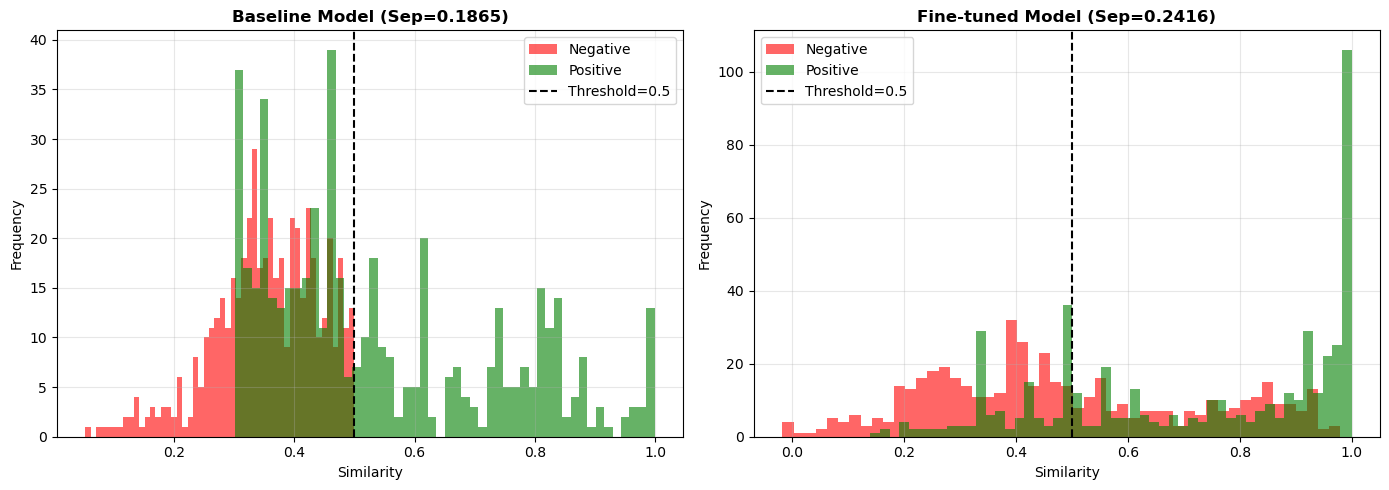


✓ Comparison plot saved to data_new/test_training_pairs_comparison.png


In [13]:
import matplotlib.pyplot as plt

# Reload baseline model for comparison (it was deleted to free GPU memory)
print("Reloading baseline model for comparison...")
baseline_model = SentenceTransformer(
    'sentence-transformers/all-mpnet-base-v2',
    device=device
)

# Also evaluate baseline on test set for fair comparison
print("Evaluating baseline model on test set for comparison...")
baseline_test_embeddings1 = baseline_model.encode(test_texts1, batch_size=64, show_progress_bar=False, convert_to_numpy=True)
baseline_test_embeddings2 = baseline_model.encode(test_texts2, batch_size=64, show_progress_bar=False, convert_to_numpy=True)

# Sanitize embeddings
baseline_test_embeddings1 = np.nan_to_num(baseline_test_embeddings1, nan=0.0, posinf=0.0, neginf=0.0)
baseline_test_embeddings2 = np.nan_to_num(baseline_test_embeddings2, nan=0.0, posinf=0.0, neginf=0.0)

# Normalize to unit vectors
baseline_test_embeddings1 = baseline_test_embeddings1 / (np.linalg.norm(baseline_test_embeddings1, axis=1, keepdims=True) + 1e-12)
baseline_test_embeddings2 = baseline_test_embeddings2 / (np.linalg.norm(baseline_test_embeddings2, axis=1, keepdims=True) + 1e-12)

baseline_test_similarities = np.sum(baseline_test_embeddings1 * baseline_test_embeddings2, axis=1)

baseline_test_pos_sims = baseline_test_similarities[test_labels_arr == 1]
baseline_test_neg_sims = baseline_test_similarities[test_labels_arr == 0]

baseline_test_sep = float(baseline_test_pos_sims.mean() - baseline_test_neg_sims.mean())
baseline_test_accuracy = float(np.mean((baseline_test_similarities > threshold).astype(int) == test_labels_arr))

print(f"\n{'='*80}")
print("COMPARISON SUMMARY")
print(f"{'='*80}")
print(f"\nSeparability (Test Set):")
print(f"  Baseline: {baseline_test_sep:.4f}")
print(f"  Fine-tuned: {finetuned_sep:.4f}")
print(f"  Improvement: {finetuned_sep - baseline_test_sep:+.4f} ({(finetuned_sep - baseline_test_sep)/baseline_test_sep*100:+.1f}%)")

print(f"\nAccuracy (Test Set):")
print(f"  Baseline: {baseline_test_accuracy:.4f}")
print(f"  Fine-tuned: {accuracy:.4f}")
print(f"  Improvement: {accuracy - baseline_test_accuracy:+.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline
axes[0].hist(baseline_test_neg_sims, bins=50, alpha=0.6, label='Negative', color='red')
axes[0].hist(baseline_test_pos_sims, bins=50, alpha=0.6, label='Positive', color='green')
axes[0].axvline(threshold, color='black', linestyle='--', label=f'Threshold={threshold}')
axes[0].set_title(f'Baseline Model (Sep={baseline_test_sep:.4f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Similarity')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Fine-tuned
axes[1].hist(test_neg_sims, bins=50, alpha=0.6, label='Negative', color='red')
axes[1].hist(test_pos_sims, bins=50, alpha=0.6, label='Positive', color='green')
axes[1].axvline(threshold, color='black', linestyle='--', label=f'Threshold={threshold}')
axes[1].set_title(f'Fine-tuned Model (Sep={finetuned_sep:.4f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Similarity')
axes[1].set_ylabel('Frequency')
axes[1].legend()

axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DATA_DIR / 'test_training_pairs_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✓ Comparison plot saved to data_new/test_training_pairs_comparison.png")

## 7. Summary and Recommendations

In [14]:
print(f"\n{'='*80}")
print("TRAINING PAIRS VALIDATION SUMMARY")
print(f"{'='*80}")
print(f"\n✓ Pairs loaded: {len(labels):,} (pos={sum(labels):,}, neg={len(labels)-sum(labels):,})")
print(f"✓ Quality metadata: Sep={metadata.get('baseline_separability'):.4f}, Status={metadata.get('quality_status')}")
print(f"✓ Model fine-tuned on {len(train_examples)} triplets (2 epochs)")
print(f"✓ Evaluated on test set ({len(test_labels)} pairs)")

if finetuned_sep > baseline_test_sep:
    print(f"\n✓ SUCCESS: Fine-tuned model shows improvement!")
    print(f"  - Separability gain: {finetuned_sep - baseline_test_sep:+.4f}")
    print(f"  - Accuracy gain: {accuracy - baseline_test_accuracy:+.4f}")
else:
    print(f"\n⚠️  Note: Fine-tuned model sep is close to baseline.")
    print(f"  - Consider training longer (more epochs) or with adjusted hyperparameters.")

print(f"\nNext steps:")
print(f"  1. Use these pairs to train production models")
print(f"  2. Evaluate against your full benchmark suite")
print(f"  3. Compare results with earlier training runs")
print(f"  4. Save the fine-tuned model if satisfied with results")


TRAINING PAIRS VALIDATION SUMMARY

✓ Pairs loaded: 10,000 (pos=5,000, neg=5,000)
✓ Quality metadata: Sep=0.3742, Status=EXCELLENT


NameError: name 'train_examples' is not defined